# 06 — Evaluation: comparing the model ladder on metrics that matter

See `docs/project_brief.md` Section 6. The argument of this notebook is that
**RMSE is the wrong headline metric for RUL**, and that a model comparison
built on it can pick the wrong model. That isn't a hypothetical here — the
results below show two models where RMSE and the domain-appropriate metric
disagree about which is better.

All three models are evaluated on the **same 100 FD001 test engines**, using
the identical feature pipeline and `random_state=42` split from Phases 3–5.

1. The NASA asymmetric scoring function — what it is and why the asymmetry
2. Full metric suite across Cox PH, Weibull AFT, and Random Survival Forest
3. Where RMSE and the NASA score disagree
4. Late-prediction rate — the operational failure mode
5. Point-estimate bias by risk bin
6. Deployment model selection, with the tradeoff stated explicitly


In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from lifelines import WeibullAFTFitter
from lifelines.utils import concordance_index
from sksurv.util import Surv

sys.path.append(str(Path("..") / "src"))
from turbofan_rul import data_loading, evaluation, features, labeling, models, plotting

plotting.style()
SUBSET, CAP, DURATION_EPS = "FD001", 125, 1e-3
DATA_DIR = Path("..") / "data" / "raw"
PROCESSED_DIR = Path("..") / "data" / "processed"
MODELS_DIR = Path("..") / "models"
MODELS_DIR.mkdir(parents=True, exist_ok=True)

## 1. The NASA asymmetric scoring function

For each engine, let $d = \widehat{RUL} - RUL_{\text{true}}$. The penalty is

$$s_i = \begin{cases} e^{d/10} - 1 & d > 0 \quad \text{(late — predicted more life than exists)} \\[4pt] e^{-d/13} - 1 & d \le 0 \quad \text{(early — predicted less life than exists)} \end{cases}$$

and the score is $\sum_i s_i$ (lower is better, 0 is perfect).

Both branches are zero at $d=0$ and grow exponentially, but the late branch
divides by the **smaller** constant, so it grows faster. That single
difference encodes the domain judgment: over-predicting remaining life means
an engine fails in service; under-predicting means a part is replaced earlier
than strictly necessary. Those are not equally bad outcomes, and the metric
says so — unlike RMSE, which treats them identically.

Implemented from the literature in `evaluation.py` rather than imported, and
unit-tested for the asymmetry property specifically (`tests/test_evaluation.py`)
— if the two constants were ever swapped, the metric would silently reward
exactly the behaviour it exists to punish.

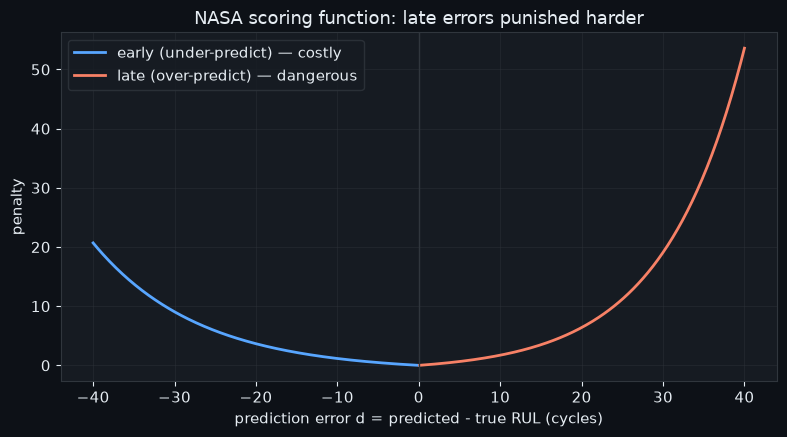

error of 10 cycles -> late penalty     1.72 | early penalty   1.16 | ratio 1.48x
error of 20 cycles -> late penalty     6.39 | early penalty   3.66 | ratio 1.75x
error of 30 cycles -> late penalty    19.09 | early penalty   9.05 | ratio 2.11x


In [2]:
errors = np.linspace(-40, 40, 400)
late_branch = np.where(errors > 0, np.exp(errors / evaluation.LATE_DECAY) - 1, np.nan)
early_branch = np.where(errors <= 0, np.exp(-errors / evaluation.EARLY_DECAY) - 1, np.nan)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(errors, early_branch, color=plotting.C0, linewidth=2, label="early (under-predict) — costly")
ax.plot(errors, late_branch, color=plotting.C1, linewidth=2, label="late (over-predict) — dangerous")
ax.axvline(0, color=plotting.GRID, linewidth=1)
ax.set_xlabel("prediction error d = predicted - true RUL (cycles)")
ax.set_ylabel("penalty")
ax.set_title("NASA scoring function: late errors punished harder")
ax.legend()
plt.tight_layout(); plt.show()

for e in [10, 20, 30]:
    late = evaluation.nasa_score(np.array([50.0]), np.array([50.0 + e]))
    early = evaluation.nasa_score(np.array([50.0]), np.array([50.0 - e]))
    print(f"error of {e:2d} cycles -> late penalty {late:8.2f} | early penalty {early:6.2f} | ratio {late/early:.2f}x")

## 2. Rebuild data and refit all three models

In [3]:
data_loading.download_cmapss(SUBSET, data_dir=DATA_DIR)
cmapss = data_loading.load_subset(SUBSET, data_dir=DATA_DIR)
kept_sensors = features.load_kept_sensors(PROCESSED_DIR / f"{SUBSET.lower()}_sensor_selection.json")

train_survival = labeling.build_train_survival_frame(cmapss.train, cap=CAP)
train_survival = features.build_feature_matrix(train_survival, kept_sensors=kept_sensors)
train_df, val_df = models.train_val_split_by_engine(train_survival, val_fraction=0.2, random_state=42)

# Curated subset for the two parametric/semi-parametric models (Phases 3-4);
# full feature set for RSF (Phase 5). Kept identical to those notebooks so
# the comparison below is like-for-like.
curated_cols = ["cycle_count"]
for s in kept_sensors:
    curated_cols += [f"{s}_roll15_mean", f"{s}_roll15_slope"]
META_COLS = {"unit_number", "time_cycles", "RUL", "duration", "event"}
full_cols = [c for c in train_survival.columns if c not in META_COLS]

train_scaled, val_scaled, scaler = models.standardize_features(train_df, val_df, curated_cols)

test_features_df = features.build_feature_matrix(cmapss.test, kept_sensors=kept_sensors)
test_survival = labeling.build_test_survival_frame(test_features_df, cmapss.rul)
test_scaled = test_survival.copy()
test_scaled[curated_cols] = scaler.transform(test_survival[curated_cols])
y_true = test_survival["true_rul"].values

print(f"{len(test_survival)} test engines | true RUL range {y_true.min()}-{y_true.max()} cycles")

100 test engines | true RUL range 7-145 cycles


In [4]:
# Cox PH -- predict_expectation gives an expected survival time usable as a
# RUL point estimate; Cox gives no natural prediction interval, which is
# itself a finding for the deployment decision below.
cox_model = models.fit_cox_ph(train_scaled, curated_cols, penalizer=0.1)
cox_pred = cox_model.predict_expectation(test_scaled[curated_cols]).values

# Weibull AFT -- median plus quantile-derived 90% interval
aft_fit_df = train_scaled.copy()
aft_fit_df["duration"] = aft_fit_df["duration"] + DURATION_EPS
aft_model = WeibullAFTFitter(penalizer=0.1)
aft_model.fit(aft_fit_df[curated_cols + ["duration", "event"]],
              duration_col="duration", event_col="event")
aft_pred = aft_model.predict_percentile(test_scaled[curated_cols], p=0.5).values
aft_low = aft_model.predict_percentile(test_scaled[curated_cols], p=0.95).values
aft_high = aft_model.predict_percentile(test_scaled[curated_cols], p=0.05).values

# Random Survival Forest -- RMST point estimate plus curve-derived interval
rsf_model = models.fit_random_survival_forest(train_df, full_cols, row_stride=3,
                                                duration_eps=DURATION_EPS)
rsf_out = models.predict_rul_from_survival(rsf_model, test_survival[full_cols])
rsf_pred = rsf_out["pred_rul"].values
rsf_low, rsf_high = rsf_out["pred_ci_low"].values, rsf_out["pred_ci_high"].values
print("All three models fitted.")

All three models fitted.


## 3. Full metric suite

Two concordance columns, because they measure different things and must not
be mixed:
- `val_cindex` -- row-level Harrell's C on every row of the 20 held-out
  training engines (the number reported in notebooks 03-05), **computed here
  from the fitted models** rather than typed in;
- `test_cindex` -- engine-level C on the 100 official test engines, from each
  model's RUL point estimate (`lifelines.utils.concordance_index`). This is
  the concordance used in later notebooks (09-12), so it's the one to
  compare against them.

In [5]:
# Held-out (row-level) concordance, computed rather than hardcoded.
val_cindex_cox = cox_model.score(val_scaled, scoring_method="concordance_index")
aft_val_df = val_scaled.copy()
aft_val_df["duration"] = aft_val_df["duration"] + DURATION_EPS
val_cindex_aft = aft_model.score(aft_val_df[curated_cols + ["duration", "event"]],
                                 scoring_method="concordance_index")
y_val = Surv.from_arrays(event=val_df["event"].astype(bool), time=val_df["duration"] + DURATION_EPS)
val_cindex_rsf = rsf_model.score(val_df[full_cols], y_val)

rows = [
    evaluation.evaluate_rul_predictions(y_true, cox_pred, model_name="Cox PH"),
    evaluation.evaluate_rul_predictions(y_true, aft_pred, aft_low, aft_high, model_name="Weibull AFT"),
    evaluation.evaluate_rul_predictions(y_true, rsf_pred, rsf_low, rsf_high, model_name="Random Survival Forest"),
]
results = pd.DataFrame(rows).set_index("model")
results["val_cindex"] = [val_cindex_cox, val_cindex_aft, val_cindex_rsf]
results["test_cindex"] = [concordance_index(y_true, p) for p in (cox_pred, aft_pred, rsf_pred)]

display(results[["nasa_score", "nasa_score_mean", "val_cindex", "test_cindex",
                  "late_prediction_rate", "interval_coverage", "rmse", "mae"]].round(3))

,nasa_score,nasa_score_mean,val_cindex,test_cindex,late_prediction_rate,interval_coverage,rmse,mae
model,,,,,,,,
Cox PH,1672.503,16.725,0.875,0.821,0.54,NaN,22.013,16.907
Weibull AFT,1288.200,12.882,0.864,0.818,0.48,0.90,23.141,18.267
Random Survival Forest,462.535,4.625,0.901,0.864,0.65,0.86,16.265,11.990


Columns are ordered by decision priority, not by convention: the NASA score
and concordance indices come first, RMSE and MAE last. Cox has no
`interval_coverage` because it produces no natural prediction interval —
a limitation that matters for a deployment requirement of "RUL + confidence."

## 4. Where RMSE and the NASA score disagree

This is the concrete payoff of the argument in the project brief, and it is
not a contrived example — it happens between two of the three models here.

In [6]:
comparison = results.loc[["Cox PH", "Weibull AFT"], ["rmse", "mae", "nasa_score"]].round(2)
display(comparison)

rmse_winner = comparison["rmse"].idxmin()
nasa_winner = comparison["nasa_score"].idxmin()
print(f"Lower (better) RMSE:       {rmse_winner}")
print(f"Lower (better) NASA score: {nasa_winner}")
if rmse_winner != nasa_winner:
    print("\nThe two metrics pick DIFFERENT models.")
    print("RMSE is symmetric, so it cannot see that one model's errors are")
    print("distributed more safely than the other's. A comparison run on RMSE")
    print("alone would select the model that is worse for maintenance decisions.")

,rmse,mae,nasa_score
model,,,
Cox PH,22.01,16.91,1672.5
Weibull AFT,23.14,18.27,1288.2


Lower (better) RMSE:       Cox PH
Lower (better) NASA score: Weibull AFT

The two metrics pick DIFFERENT models.
RMSE is symmetric, so it cannot see that one model's errors are
distributed more safely than the other's. A comparison run on RMSE
alone would select the model that is worse for maintenance decisions.


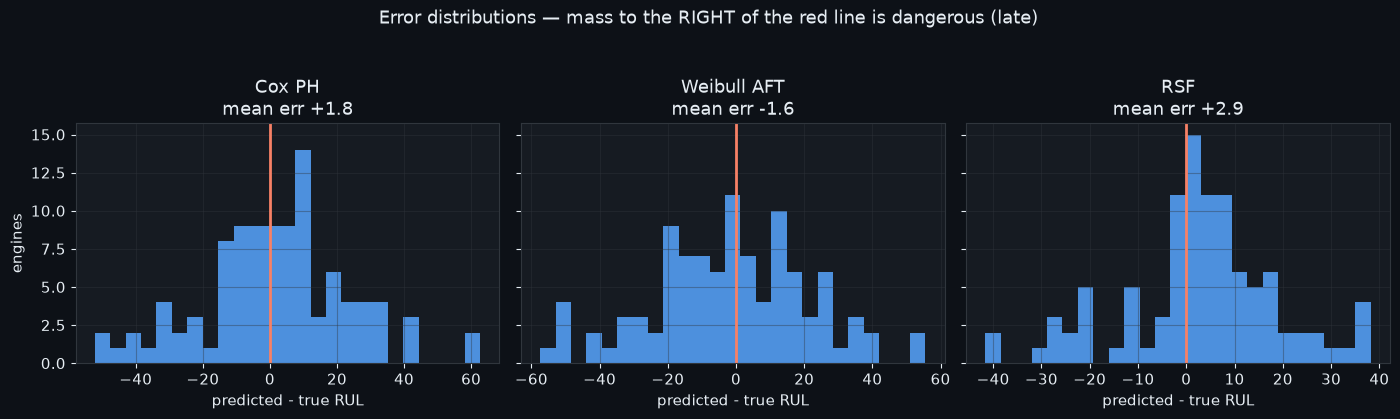

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, (name, pred) in zip(axes, [("Cox PH", cox_pred), ("Weibull AFT", aft_pred),
                                     ("RSF", rsf_pred)]):
    err = pred - y_true
    ax.hist(err, bins=25, color=plotting.C0, alpha=0.85)
    ax.axvline(0, color=plotting.C1, linewidth=2)
    ax.set_title(f"{name}\nmean err {err.mean():+.1f}")
    ax.set_xlabel("predicted - true RUL")
axes[0].set_ylabel("engines")
fig.suptitle("Error distributions — mass to the RIGHT of the red line is dangerous (late)", y=1.04)
plt.tight_layout(); plt.show()

## 5. Late-prediction rate: the operational failure mode

An aggregate score can hide how often a model is late, so it is reported
separately. This is where the comparison gets genuinely interesting rather
than a clean sweep.

In [8]:
late = results[["late_prediction_rate", "nasa_score", "mae"]].round(3).sort_values("nasa_score")
display(late)

worst_late = results["late_prediction_rate"].idxmax()
best_nasa = results["nasa_score"].idxmin()
print(f"Highest late-prediction rate: {worst_late} ({results.loc[worst_late, 'late_prediction_rate']:.0%})")
print(f"Best NASA score:              {best_nasa} ({results.loc[best_nasa, 'nasa_score']:.0f})")
if worst_late == best_nasa:
    print("\nSame model -- it is late MORE OFTEN, but by much SMALLER margins.")
    print("Because the NASA penalty is exponential, many small late errors cost")
    print("far less than a few large ones. Frequency and severity are different")
    print("questions, and only reporting both makes that visible.")

,late_prediction_rate,nasa_score,mae
model,,,
Random Survival Forest,0.65,462.535,11.990
Weibull AFT,0.48,1288.200,18.267
Cox PH,0.54,1672.503,16.907


Highest late-prediction rate: Random Survival Forest (65%)
Best NASA score:              Random Survival Forest (463)

Same model -- it is late MORE OFTEN, but by much SMALLER margins.
Because the NASA penalty is exponential, many small late errors cost
far less than a few large ones. Frequency and severity are different
questions, and only reporting both makes that visible.


## 6. Point-estimate bias by risk bin

Test engines are split into five equal-sized bins by each model's
**predicted** RUL (bin 0 = lowest predicted RUL = highest predicted risk),
and each bin's mean prediction is compared with its mean true RUL. This
checks whether point estimates are biased in a particular part of the risk
range. It is not a survival-curve calibration check, and it says nothing
about whether the intervals are calibrated -- that's `interval_coverage`
above.

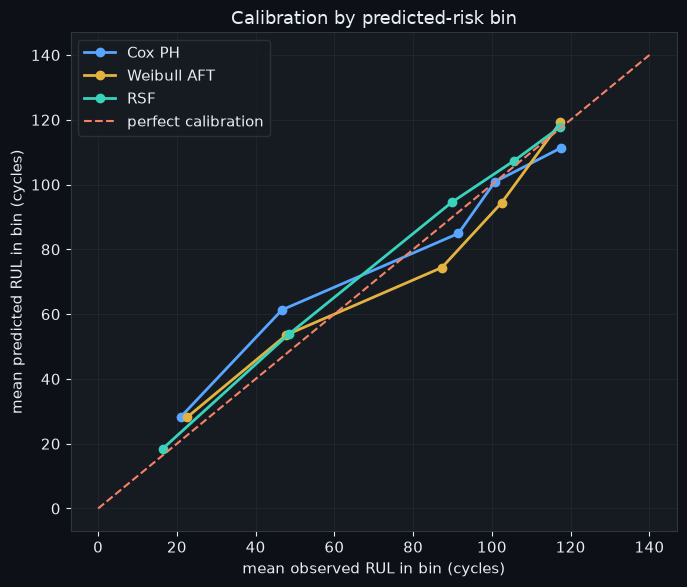

RSF calibration detail (positive bias = over-predicting = late):


,bin,n,mean_predicted,mean_observed,bias
0,0,20,18.51,16.45,2.06
1,1,20,53.83,48.45,5.38
2,2,20,94.48,89.75,4.73
3,3,20,107.30,105.55,1.75
4,4,20,117.87,117.40,0.47


In [9]:
fig, ax = plt.subplots(figsize=(7, 6))
for (name, pred), colour in zip(
    [("Cox PH", cox_pred), ("Weibull AFT", aft_pred), ("RSF", rsf_pred)],
    [plotting.C0, plotting.GOLD, plotting.TEAL],
):
    cal = evaluation.calibration_by_risk_bin(y_true, pred, n_bins=5)
    ax.plot(cal["mean_observed"], cal["mean_predicted"], "o-", color=colour, label=name, linewidth=2)

lims = [0, 140]
ax.plot(lims, lims, "--", color=plotting.C1, linewidth=1.5, label="perfect calibration")
ax.set_xlabel("mean observed RUL in bin (cycles)")
ax.set_ylabel("mean predicted RUL in bin (cycles)")
ax.set_title("Calibration by predicted-risk bin")
ax.legend(); plt.tight_layout(); plt.show()

print("RSF calibration detail (positive bias = over-predicting = late):")
display(evaluation.calibration_by_risk_bin(y_true, rsf_pred, n_bins=5).round(2))

Points above the diagonal mean a model over-predicts remaining life for
that risk band — the dangerous direction. The bin with the **lowest**
predicted RUL matters most operationally: those are the engines the model
thinks are closest to failure, where being late is least acceptable.

## 7. Deployment model selection

The choice is stated against the table above rather than asserted.

In [10]:
summary = results[["nasa_score", "val_cindex", "test_cindex", "late_prediction_rate",
                    "interval_coverage", "rmse", "mae"]].round(3)
display(summary)
summary.to_csv(PROCESSED_DIR / "model_comparison_fd001.csv")
print(f"Saved comparison table to {PROCESSED_DIR / 'model_comparison_fd001.csv'}")

,nasa_score,val_cindex,test_cindex,late_prediction_rate,interval_coverage,rmse,mae
model,,,,,,,
Cox PH,1672.503,0.875,0.821,0.54,NaN,22.013,16.907
Weibull AFT,1288.200,0.864,0.818,0.48,0.90,23.141,18.267
Random Survival Forest,462.535,0.901,0.864,0.65,0.86,16.265,11.990


Saved comparison table to ..\data\processed\model_comparison_fd001.csv


### Decision

**Random Survival Forest is the deployment model**, on the evidence above:
the best NASA score by a wide margin, the best concordance on both measures
(held-out and test), and the best RMSE/MAE. Its advantage is consistent with
Phase 3's finding that the proportional-hazards assumption doesn't describe
this data well — the model that drops that assumption wins, as the project
brief predicted.

**But RSF does not dominate on every axis, and the deployment design has to
account for that:**

1. **Its 90% intervals under-cover** (86% vs. Weibull's 90.0%) — slightly
   overconfident.
2. **It cannot predict beyond the training time ceiling** (~125 cycles, per
   Phase 5), so it structurally under-predicts the healthiest engines.
   Weibull, being parametric, extrapolates freely.
3. **It is late more often** than the other two, though by smaller margins.

So the API in Phase 8 serves **RSF for the point estimate and risk ranking**,
with **Weibull AFT retained for the confidence interval** — using each model
for what the evaluation actually shows it does best, rather than shipping a
single model because it won the headline number. Cox PH is not deployed: RSF
beats it on every metric here, and Cox produces no natural prediction
interval, which the "RUL + confidence" requirement needs. (Cox does beat
Weibull on concordance, RMSE and MAE -- Weibull is kept for its interval,
not for its point accuracy.)

### On the two disagreements worth carrying into an interview

- **RMSE and the NASA score rank Cox and Weibull differently.** Weibull has
  the worse RMSE but the better NASA score, because its errors sit on the
  safer side. A comparison run on RMSE alone would have picked the worse
  model for the actual maintenance decision.
- **The model with the best NASA score also has the highest late rate.**
  Frequency and severity are separate questions; an exponential penalty
  means many small late errors cost less than a few catastrophic ones.
  Reporting only one of the two would hide this.
